# Notebook 6 — Adaptive Strategy Selection via Market Regime Detection

## Overview

No single strategy dominates across all market environments. Trend-following strategies excel in sustained directional markets but underperform in choppy, mean-reverting regimes. Mean-reversion strategies thrive in low-volatility, range-bound conditions but can suffer severe losses during strong trends.

**Adaptive Strategy Selection** aims to identify the current market regime in real time (using only past data) and select the strategy most suited to that regime.

### Framework Architecture

```
Raw Data → Regime Indicators → Regime Classifier → Strategy Router → Portfolio
```

### Market Regime Definition

We define four regimes based on two dimensions:

| Regime | Trend Strength | Volatility | Favoured Strategy |
|--------|---------------|------------|-------------------|
| Bull Trend | High (ADX > 25) | Low–Medium | Trend / Momentum |
| Bear Trend | High (ADX > 25) | High | Cash / Defensive |
| Mean-Reverting | Low (ADX < 20) | Low | Mean Reversion |
| High Volatility | Any | High | Mean Reversion / Breakout |

### Regime Indicators

**1. ADX (Average Directional Index)** — measures trend strength (not direction):
$$\text{ADX}_t = \frac{1}{n}\sum \left|\frac{+DI - -DI}{+DI + -DI}\right| \times 100$$

**2. Historical Volatility (HV)** — 21-day annualised standard deviation of log returns:
$$\text{HV}_t = \sqrt{252} \cdot \sigma_{\text{log-ret}, 21}$$

**3. Hurst Exponent** — distinguishes trending (H > 0.5) from mean-reverting (H < 0.5).

**4. 200-day SMA direction filter** — determines bull vs. bear regime.

### Regime Classification

Using rolling quantiles of ADX and HV (computed on training data to avoid look-ahead):

$$\text{Regime}_t = \begin{cases}
\text{Bull Trend}        & \text{if ADX} > q_{60}(\text{ADX}) \text{ and Price} > \text{SMA200} \text{ and HV} \leq q_{70}(\text{HV}) \\
\text{Bear/Volatile}     & \text{if ADX} > q_{60}(\text{ADX}) \text{ and Price} < \text{SMA200} \\
\text{Mean-Reverting}    & \text{if ADX} \leq q_{40}(\text{ADX}) \text{ and HV} \leq q_{50}(\text{HV}) \\
\text{High Volatility}   & \text{if HV} > q_{70}(\text{HV}) \\
\text{Transitional}      & \text{otherwise}
\end{cases}$$

### Strategy Allocation

| Regime | Strategy Activated | Weight |
|--------|-------------------|--------|
| Bull Trend | Trend Momentum + MA Crossover | 60% / 40% |
| Mean-Reverting | Mean Reversion | 100% |
| High Volatility | Breakout (momentum spike) | 100% |
| Bear/Volatile | Cash (no position) | 0% |
| Transitional | MA Crossover only | 100% |

### Anti-Overfitting Safeguards
- Regime thresholds are computed from training-set quantiles only.
- No fitting on test data at any stage.
- A **regime persistence filter** (minimum 5-day regime duration) prevents hyper-reactive switching.
- All component strategy signals are identical to those used in Notebooks 1–5.

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from modules.data_loader  import load_data, split_data
from modules.indicators   import (
    sma, ema, roc, rsi, macd, atr, adx as compute_adx,
    bollinger_bands, donchian_channel, zscore, historical_volatility
)
from modules.backtester   import Backtester, benchmark_metrics, compute_metrics
from modules.performance  import (
    plot_equity_and_drawdown, plot_rolling_sharpe,
    plot_monthly_returns_heatmap, plot_return_distribution,
    metrics_to_dataframe, print_metrics_table
)

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data and Establish Splits

In [2]:
df = load_data()
train, val, test = split_data(df, train_end='2021-12-31', val_end='2023-06-30')
print(f'Dataset : {len(df):,} days')
print(f'Train   : {len(train):,} days  ({train.index.min().date()} → {train.index.max().date()})')
print(f'Val     : {len(val):,} days  ({val.index.min().date()}   → {val.index.max().date()})')
print(f'Test    : {len(test):,} days  ({test.index.min().date()}  → {test.index.max().date()})')

Dataset : 2,478 days
Train   : 1,486 days  (2016-01-01 → 2021-12-31)
Val     : 370 days  (2022-01-03   → 2023-06-30)
Test    : 622 days  (2023-07-03  → 2026-01-01)


## 2. Compute All Regime Indicators

In [3]:
close  = df['CLOSE']
high   = df['HIGH']
low    = df['LOW']
volume = df['SHARES_TRADED']

# Trend direction
sma200    = sma(close, 200)

# Trend strength
adx_df    = compute_adx(high, low, close, 14)
adx_vals  = adx_df['adx']
plus_di   = adx_df['plus_di']
minus_di  = adx_df['minus_di']

# Volatility regime
hv21      = historical_volatility(close, 21)

# Short-term momentum
rsi14     = rsi(close, 14)
macd_df   = macd(close, 12, 26, 9)

print('Regime indicators computed.')
print(f'ADX range (training):  [{adx_vals.reindex(train.index).dropna().min():.1f}, '
      f'{adx_vals.reindex(train.index).dropna().max():.1f}]')
print(f'HV21 range (training): [{hv21.reindex(train.index).dropna().min():.2f}, '
      f'{hv21.reindex(train.index).dropna().max():.2f}]')

Regime indicators computed.
ADX range (training):  [8.8, 76.9]
HV21 range (training): [0.05, 0.89]


## 3. Compute Regime Thresholds from Training Data Only

**Critical**: All quantile thresholds are computed exclusively on the training set. They are then applied as fixed constants to the validation and test sets. This prevents look-ahead bias in the regime classification.

In [4]:
# Compute quantile thresholds from training data
train_adx = adx_vals.reindex(train.index).dropna()
train_hv  = hv21.reindex(train.index).dropna()

ADX_TREND_Q    = 0.60  # top 40% ADX = trending
ADX_RANGE_Q    = 0.40  # bottom 40% ADX = ranging
HV_HIGH_Q      = 0.70  # top 30% HV = high volatility
HV_MED_Q       = 0.50  # median HV

adx_trend_thr  = train_adx.quantile(ADX_TREND_Q)
adx_range_thr  = train_adx.quantile(ADX_RANGE_Q)
hv_high_thr    = train_hv.quantile(HV_HIGH_Q)
hv_med_thr     = train_hv.quantile(HV_MED_Q)

REGIME_PERSIST  = 5  # minimum days to stay in a regime before switching

print('=== Regime Thresholds (computed from training data only) ===')
print(f'ADX trend threshold  (q{ADX_TREND_Q:.0%}): {adx_trend_thr:.2f}')
print(f'ADX range threshold  (q{ADX_RANGE_Q:.0%}): {adx_range_thr:.2f}')
print(f'HV high threshold    (q{HV_HIGH_Q:.0%}): {hv_high_thr:.4f}  ({hv_high_thr*100:.1f}% ann. vol)')
print(f'HV median threshold  (q{HV_MED_Q:.0%}): {hv_med_thr:.4f}  ({hv_med_thr*100:.1f}% ann. vol)')
print(f'Regime persistence   : {REGIME_PERSIST} days')

=== Regime Thresholds (computed from training data only) ===
ADX trend threshold  (q60%): 27.93
ADX range threshold  (q40%): 20.80
HV high threshold    (q70%): 0.1518  (15.2% ann. vol)
HV median threshold  (q50%): 0.1239  (12.4% ann. vol)
Regime persistence   : 5 days


## 4. Regime Classification Function

In [5]:
REGIME_BULL     = 'Bull Trend'
REGIME_BEAR     = 'Bear/Volatile'
REGIME_MEAN_REV = 'Mean-Reverting'
REGIME_HIGH_VOL = 'High Volatility'
REGIME_TRANS    = 'Transitional'

def classify_regimes(
    close, sma200, adx_vals, hv_vals,
    adx_trend_thr, adx_range_thr, hv_high_thr, hv_med_thr,
    persist_days=5
):
    """Classify market regime at each date.

    Returns a pd.Series of regime labels.
    Uses a persistence filter: regime must hold for `persist_days`
    consecutive days before it officially changes.
    """
    raw_regime = pd.Series(REGIME_TRANS, index=close.index)

    for date in close.index:
        adx = adx_vals.loc[date]
        hv  = hv_vals.loc[date]
        p   = close.loc[date]
        s   = sma200.loc[date]

        if pd.isna(adx) or pd.isna(hv) or pd.isna(s):
            raw_regime.loc[date] = REGIME_TRANS
            continue

        above_sma = p > s
        trending  = adx > adx_trend_thr
        ranging   = adx < adx_range_thr
        hi_vol    = hv > hv_high_thr
        low_vol   = hv < hv_med_thr

        if hi_vol and not (trending and above_sma):
            raw_regime.loc[date] = REGIME_HIGH_VOL
        elif trending and above_sma and not hi_vol:
            raw_regime.loc[date] = REGIME_BULL
        elif trending and not above_sma:
            raw_regime.loc[date] = REGIME_BEAR
        elif ranging and low_vol:
            raw_regime.loc[date] = REGIME_MEAN_REV
        else:
            raw_regime.loc[date] = REGIME_TRANS

    # Persistence filter: carry forward previous regime until new one
    # has persisted for `persist_days` days
    regime = raw_regime.copy()
    current_regime = raw_regime.iloc[0]
    pending_regime = raw_regime.iloc[0]
    pending_count  = 0

    for i in range(len(raw_regime)):
        r = raw_regime.iloc[i]
        if r == current_regime:
            pending_regime = r
            pending_count  = 0
        else:
            if r == pending_regime:
                pending_count += 1
            else:
                pending_regime = r
                pending_count  = 1
            if pending_count >= persist_days:
                current_regime = pending_regime
                pending_count  = 0
        regime.iloc[i] = current_regime

    return regime


regime = classify_regimes(
    close, sma200, adx_vals, hv21,
    adx_trend_thr, adx_range_thr, hv_high_thr, hv_med_thr,
    persist_days=REGIME_PERSIST
)

print('Regime distribution (full period):')
print(regime.value_counts())
print()
print('Regime distribution (%):')
print((regime.value_counts() / len(regime) * 100).round(1))

Regime distribution (full period):
Transitional       693
Mean-Reverting     599
High Volatility    563
Bull Trend         547
Bear/Volatile       76
Name: count, dtype: int64

Regime distribution (%):
Transitional       28.0
Mean-Reverting     24.2
High Volatility    22.7
Bull Trend         22.1
Bear/Volatile       3.1
Name: count, dtype: float64


## 5. Visualise Market Regimes

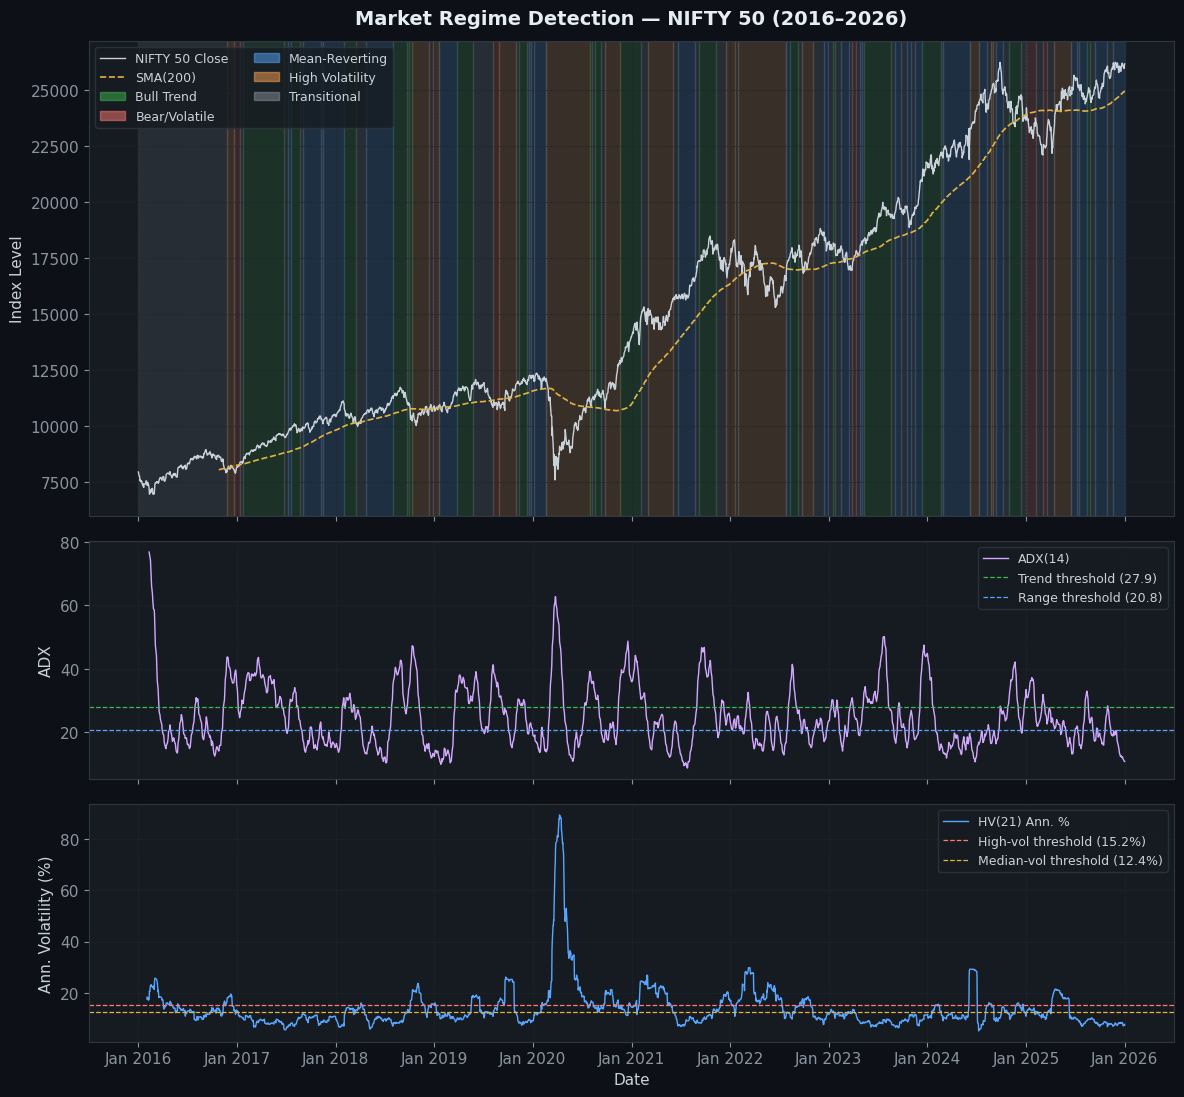

In [6]:
REGIME_COLOURS = {
    REGIME_BULL:     '#3fb950',   # green
    REGIME_BEAR:     '#ff7b72',   # red
    REGIME_MEAN_REV: '#58a6ff',   # blue
    REGIME_HIGH_VOL: '#ffa657',   # orange
    REGIME_TRANS:    '#8b949e',   # grey
}

fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1.5, 1.5], 'hspace': 0.08})

# Panel 1: Price + regime background
ax1 = axes[0]
ax1.plot(close.index, close.values, color='#c9d1d9', linewidth=1.0, zorder=3, label='NIFTY 50 Close')
ax1.plot(sma200.index, sma200.values, color='#e3b341', linewidth=1.2, linestyle='--',
         zorder=4, label='SMA(200)')

prev_date = close.index[0]
prev_reg  = regime.iloc[0]
for i in range(1, len(regime)):
    if regime.iloc[i] != prev_reg or i == len(regime) - 1:
        ax1.axvspan(prev_date, regime.index[i],
                    alpha=0.15, color=REGIME_COLOURS[prev_reg], zorder=1)
        prev_date = regime.index[i]
        prev_reg  = regime.iloc[i]

ax1.set_title('Market Regime Detection — NIFTY 50 (2016–2026)', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('Index Level')

patches = [mpatches.Patch(color=REGIME_COLOURS[r], alpha=0.5, label=r) for r in REGIME_COLOURS]
ax1.legend(handles=[ax1.get_lines()[0], ax1.get_lines()[1]] + patches,
           loc='upper left', fontsize=9, ncol=2)
ax1.grid(True)

# Panel 2: ADX
ax2 = axes[1]
ax2.plot(adx_vals.index, adx_vals.values, color='#d2a8ff', linewidth=1.0, label='ADX(14)')
ax2.axhline(adx_trend_thr, color='#3fb950', linewidth=0.9, linestyle='--',
            label=f'Trend threshold ({adx_trend_thr:.1f})')
ax2.axhline(adx_range_thr, color='#58a6ff', linewidth=0.9, linestyle='--',
            label=f'Range threshold ({adx_range_thr:.1f})')
ax2.set_ylabel('ADX')
ax2.legend(fontsize=9)
ax2.grid(True)

# Panel 3: Historical Volatility
ax3 = axes[2]
ax3.plot(hv21.index, hv21.values * 100, color='#58a6ff', linewidth=1.0, label='HV(21) Ann. %')
ax3.axhline(hv_high_thr * 100, color='#ff7b72', linewidth=0.9, linestyle='--',
            label=f'High-vol threshold ({hv_high_thr*100:.1f}%)')
ax3.axhline(hv_med_thr * 100, color='#e3b341', linewidth=0.9, linestyle='--',
            label=f'Median-vol threshold ({hv_med_thr*100:.1f}%)')
ax3.set_ylabel('Ann. Volatility (%)')
ax3.set_xlabel('Date')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.legend(fontsize=9)
ax3.grid(True)

plt.tight_layout()
plt.show()

## 6. Build Component Strategy Signals

We replicate the signals from Notebooks 1–5 here (identical parameters). No re-fitting.

In [7]:
# --- Strategy 1: Trend Momentum (Notebook 1) ---
roc252    = roc(close, 252)
sma200_   = sma200
adx_14    = adx_vals

entry_trend = (roc252 > 0) & (close > sma200_) & (adx_14 > 20)
exit_trend  = (roc252 < 0) | (close < sma200_) | (adx_14 < 15)

sig_trend = pd.Series(0, index=df.index)
in_p = False
for date in df.index:
    if pd.isna(roc252.loc[date]) or pd.isna(sma200_.loc[date]) or pd.isna(adx_14.loc[date]):
        continue
    if not in_p and entry_trend.loc[date]:
        in_p = True
    elif in_p and exit_trend.loc[date]:
        in_p = False
    sig_trend.loc[date] = 1 if in_p else 0

print(f'Trend signal:       {sig_trend.mean()*100:.1f}% exposure, '
      f'{int(sig_trend.diff().clip(lower=0).sum())} entries')

# --- Strategy 2: Mean Reversion (Notebook 2) ---
z20    = zscore(close, 20)
rsi14_ = rsi14

sig_mr  = pd.Series(0, index=df.index)
in_p    = False
days_in = 0
for i, date in enumerate(df.index):
    if pd.isna(z20.iloc[i]) or pd.isna(rsi14_.iloc[i]) or pd.isna(sma200_.iloc[i]):
        continue
    if not in_p:
        if z20.iloc[i] < -1.5 and rsi14_.iloc[i] < 35 and close.iloc[i] > sma200_.iloc[i]:
            in_p = True; days_in = 0
    else:
        days_in += 1
        if z20.iloc[i] > 0.0 or rsi14_.iloc[i] > 60 or days_in >= 10:
            in_p = False; days_in = 0
    sig_mr.iloc[i] = 1 if in_p else 0

print(f'Mean Rev signal:    {sig_mr.mean()*100:.1f}% exposure, '
      f'{int(sig_mr.diff().clip(lower=0).sum())} entries')

# --- Strategy 3: MA Crossover (Notebook 5, 20/50 EMA + MACD) ---
ema20  = ema(close, 20)
ema50  = ema(close, 50)
hist   = macd_df['histogram']

sig_mac = pd.Series(0, index=df.index)
in_p    = False
for date in df.index:
    if pd.isna(ema20.loc[date]) or pd.isna(ema50.loc[date]) or pd.isna(hist.loc[date]):
        continue
    bull_cross = ema20.loc[date] > ema50.loc[date]
    macd_ok    = hist.loc[date] > 0
    if not in_p and bull_cross and macd_ok:
        in_p = True
    elif in_p and (not bull_cross or hist.loc[date] < 0):
        in_p = False
    sig_mac.loc[date] = 1 if in_p else 0

print(f'MAC signal:         {sig_mac.mean()*100:.1f}% exposure, '
      f'{int(sig_mac.diff().clip(lower=0).sum())} entries')

# --- Strategy 4: Breakout (Notebook 4) ---
dc_entry = donchian_channel(high, low, 20)
dc_exit_  = donchian_channel(high, low, 10)
atr14_   = atr(high, low, close, 14)
vol_sma20 = sma(volume.astype(float), 20)

prev_dc_upper  = dc_entry['upper'].shift(1)
prev_dc_lower  = dc_exit_['lower'].shift(1)

sig_bo  = pd.Series(0, index=df.index)
in_p    = False; entry_px = atr_at_entry = None; dheld = 0

for i, date in enumerate(df.index):
    if pd.isna(prev_dc_upper.iloc[i]) or pd.isna(atr14_.iloc[i]):
        continue
    p = close.iloc[i]
    v = volume.iloc[i]
    if not in_p:
        if (p > prev_dc_upper.iloc[i] and
            not pd.isna(vol_sma20.iloc[i]) and v > vol_sma20.iloc[i] and
            not pd.isna(adx_14.iloc[i]) and adx_14.iloc[i] > 20):
            in_p = True; entry_px = p; atr_at_entry = atr14_.iloc[i]; dheld = 0
    else:
        dheld += 1
        atr_stop = entry_px - 2.0 * atr_at_entry
        if (p < prev_dc_lower.iloc[i] if not pd.isna(prev_dc_lower.iloc[i]) else False) or \
           p < atr_stop or dheld >= 60:
            in_p = False; entry_px = atr_at_entry = None; dheld = 0
    sig_bo.iloc[i] = 1 if in_p else 0

print(f'Breakout signal:    {sig_bo.mean()*100:.1f}% exposure, '
      f'{int(sig_bo.diff().clip(lower=0).sum())} entries')

Trend signal:       54.0% exposure, 41 entries
Mean Rev signal:    4.7% exposure, 17 entries
MAC signal:         35.2% exposure, 81 entries


Breakout signal:    28.2% exposure, 28 entries


## 7. Adaptive Strategy Router

At each day, the router selects which strategy's signal to follow based on the current regime.

In [8]:
def adaptive_signal(
    regime: pd.Series,
    sig_trend: pd.Series,
    sig_mr: pd.Series,
    sig_mac: pd.Series,
    sig_bo: pd.Series,
) -> pd.Series:
    """Composite adaptive signal based on regime.

    Bull Trend    → 60% Trend Momentum + 40% MA Crossover (round to 0 or 1)
    Mean-Reverting→ Mean Reversion signal
    High Volatility→ Breakout signal
    Bear/Volatile → Cash (0)
    Transitional  → MA Crossover signal
    """
    signal = pd.Series(0.0, index=regime.index)

    for date in regime.index:
        r = regime.loc[date]
        if r == REGIME_BULL:
            # Blended: take position if at least one of the two signals is on
            # Weighted: 0.6 * trend + 0.4 * mac, threshold at 0.3
            blend = 0.6 * sig_trend.loc[date] + 0.4 * sig_mac.loc[date]
            signal.loc[date] = 1 if blend >= 0.3 else 0
        elif r == REGIME_MEAN_REV:
            signal.loc[date] = sig_mr.loc[date]
        elif r == REGIME_HIGH_VOL:
            signal.loc[date] = sig_bo.loc[date]
        elif r == REGIME_BEAR:
            signal.loc[date] = 0   # defensive — cash
        else:  # Transitional
            signal.loc[date] = sig_mac.loc[date]

    return signal.astype(int)


adaptive_sig = adaptive_signal(regime, sig_trend, sig_mr, sig_mac, sig_bo)

print(f'Adaptive signal exposure : {adaptive_sig.mean()*100:.1f}%')
print(f'Adaptive entries         : {int(adaptive_sig.diff().clip(lower=0).sum())}')
print()
print('Regime breakdown of active positions:')
for r in [REGIME_BULL, REGIME_MEAN_REV, REGIME_HIGH_VOL, REGIME_BEAR, REGIME_TRANS]:
    days_in_regime = (regime == r).sum()
    days_active    = ((regime == r) & (adaptive_sig == 1)).sum()
    if days_in_regime > 0:
        print(f'  {r:<20}: {days_in_regime:>4} days, active {days_active:>4} days '
              f'({days_active/days_in_regime*100:.1f}%)')

Adaptive signal exposure : 33.7%
Adaptive entries         : 51

Regime breakdown of active positions:
  Bull Trend          :  547 days, active  526 days (96.2%)
  Mean-Reverting      :  599 days, active   31 days (5.2%)
  High Volatility     :  563 days, active   98 days (17.4%)
  Bear/Volatile       :   76 days, active    0 days (0.0%)
  Transitional        :  693 days, active  179 days (25.8%)


## 8. Backtest — Adaptive vs All Individual Strategies

In [9]:
INITIAL_CAPITAL = 100_000
COST_BPS        = 10

def run_backtest(sig):
    bt = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=COST_BPS)
    return bt.run(sig)

res_adaptive = run_backtest(adaptive_sig)
res_trend    = run_backtest(sig_trend)
res_mr       = run_backtest(sig_mr)
res_mac      = run_backtest(sig_mac)
res_bo       = run_backtest(sig_bo)

bh_ret = df['CLOSE'].pct_change().fillna(0)
bh_eq  = INITIAL_CAPITAL * (1 + bh_ret).cumprod()

print('Final portfolio values:')
print(f'  Adaptive  : ₹{res_adaptive.portfolio_val.iloc[-1]:>12,.2f}')
print(f'  Trend Mom : ₹{res_trend.portfolio_val.iloc[-1]:>12,.2f}')
print(f'  Mean Rev  : ₹{res_mr.portfolio_val.iloc[-1]:>12,.2f}')
print(f'  MA Cross  : ₹{res_mac.portfolio_val.iloc[-1]:>12,.2f}')
print(f'  Breakout  : ₹{res_bo.portfolio_val.iloc[-1]:>12,.2f}')
print(f'  Benchmark : ₹{bh_eq.iloc[-1]:>12,.2f}')

Final portfolio values:
  Adaptive  : ₹  147,913.31
  Trend Mom : ₹  122,985.86
  Mean Rev  : ₹  114,450.53
  MA Cross  : ₹  127,566.43
  Breakout  : ₹  118,393.63
  Benchmark : ₹  328,342.25


## 9. Equity Curve — Adaptive vs All Strategies

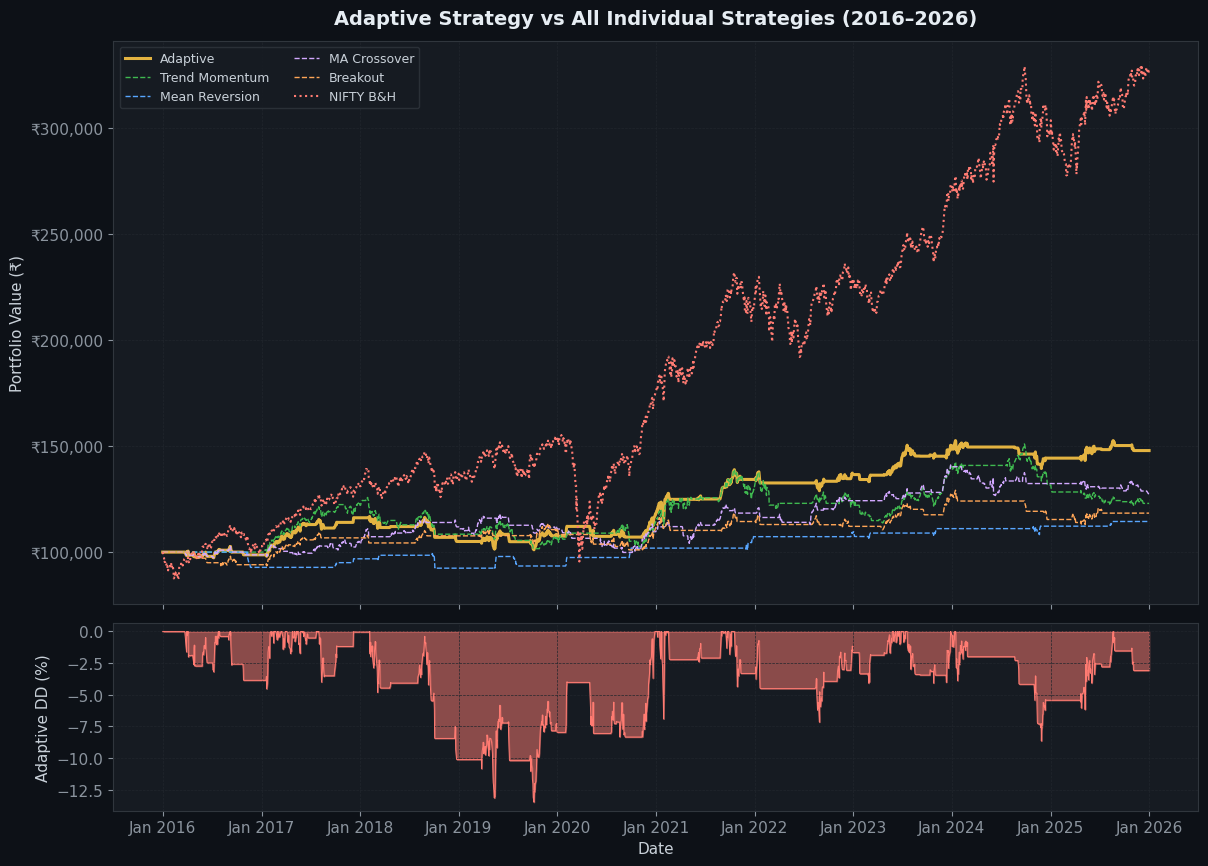

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05})

curves = {
    'Adaptive':          (res_adaptive.portfolio_val, '#e3b341',   2.2, '-'),
    'Trend Momentum':    (res_trend.portfolio_val,    '#3fb950',   1.0, '--'),
    'Mean Reversion':    (res_mr.portfolio_val,       '#58a6ff',   1.0, '--'),
    'MA Crossover':      (res_mac.portfolio_val,      '#d2a8ff',   1.0, '--'),
    'Breakout':          (res_bo.portfolio_val,       '#ffa657',   1.0, '--'),
    'NIFTY B&H':         (bh_eq,                      '#ff7b72',   1.5, ':'),
}

for label, (eq, col, lw, ls) in curves.items():
    ax1.plot(eq.index, eq.values, color=col, linewidth=lw, linestyle=ls, label=label)

ax1.set_title('Adaptive Strategy vs All Individual Strategies (2016–2026)',
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('Portfolio Value (₹)')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'₹{x:,.0f}'))
ax1.legend(fontsize=9, ncol=2)
ax1.grid(True)

# Drawdown for adaptive
cum  = (1 + res_adaptive.returns.dropna()).cumprod()
peak = cum.cummax()
dd   = (cum - peak) / peak * 100
ax2.fill_between(dd.index, dd.values, 0, color='#ff7b72', alpha=0.5)
ax2.plot(dd.index, dd.values, color='#ff7b72', linewidth=0.7)
ax2.set_ylabel('Adaptive DD (%)')
ax2.set_xlabel('Date')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.grid(True)

plt.tight_layout()
plt.show()

## 10. Comprehensive Performance Comparison

In [11]:
bm_m = benchmark_metrics(df, initial_capital=INITIAL_CAPITAL)

strategies = [
    ('Adaptive',       res_adaptive),
    ('Trend Momentum', res_trend),
    ('Mean Reversion', res_mr),
    ('MA Crossover',   res_mac),
    ('Breakout',       res_bo),
]

print(f'{'Strategy':<20} {'CAGR%':>7} {'Sharpe':>7} {'Sortino':>8} {'MaxDD%':>8} {'WinRate%':>9} {'Calmar':>7}')
print('=' * 75)
for name, res in strategies:
    m = res.metrics
    print(f"{name:<20} {m['cagr_pct']:>7.2f} {m['sharpe_ratio']:>7.3f} "
          f"{m['sortino_ratio']:>8.3f} {m['max_drawdown_pct']:>8.2f} "
          f"{m['win_rate_pct']:>9.2f} {m['calmar_ratio']:>7.3f}")

print(f"{'NIFTY B&H':<20} {bm_m['cagr_pct']:>7.2f} {bm_m['sharpe_ratio']:>7.3f} "
      f"{bm_m['sortino_ratio']:>8.3f} {bm_m['max_drawdown_pct']:>8.2f} "
      f"{bm_m['win_rate_pct']:>9.2f} {bm_m['calmar_ratio']:>7.3f}")

Strategy               CAGR%  Sharpe  Sortino   MaxDD%  WinRate%  Calmar
Adaptive                4.06  -0.289   -0.024   -13.47     18.28   0.301
Trend Momentum          2.13  -0.406   -0.029   -19.37     28.81   0.110
Mean Reversion          1.38  -1.357   -0.125    -7.62      2.58   0.181
MA Crossover            2.51  -0.528   -0.040   -15.50     19.45   0.162
Breakout                1.73  -0.712   -0.056   -12.47     15.46   0.139
NIFTY B&H              12.86   0.440    0.026   -38.44     54.30   0.334


## 11. Detailed Adaptive Strategy Metrics

In [12]:
print_metrics_table(
    res_adaptive.metrics,
    title='Adaptive Strategy vs NIFTY 50 Buy & Hold',
    benchmark_metrics=bm_m
)
metrics_to_dataframe(res_adaptive.metrics, bm_m, strategy_name='Adaptive Strategy')


  Adaptive Strategy vs NIFTY 50 Buy & Hold
Metric                               Strategy      Benchmark
------------------------------------------------------------
  Total Return (%)                     47.910        228.340
  CAGR (%)                              4.060         12.860
  Ann. Volatility (%)                   7.140         16.200
  Sharpe Ratio                         -0.289          0.440
  Sortino Ratio                        -0.024          0.026
  Calmar Ratio                          0.301          0.334
  Max Drawdown (%)                    -13.470        -38.440
  Avg DD Duration (days)               49.500         19.000
  Longest DD (days)                       714            314
  Win Rate (%)                         18.280         54.300
  Avg Win (%)                           0.585          0.681
  Avg Loss (%)                         -0.518         -0.694
  Profit Factor                         1.186          1.168
  VaR 95% (%)                          -0

,Adaptive Strategy,NIFTY 50 B&H
Total Return (%),47.910,228.340
CAGR (%),4.060,12.860
Ann. Volatility (%),7.140,16.200
Sharpe Ratio,-0.289,0.440
Sortino Ratio,-0.024,0.026
Calmar Ratio,0.301,0.334
Max Drawdown (%),-13.470,-38.440
Avg DD Duration (days),49.500,19.000
Longest DD (days),714.000,314.000
Win Rate (%),18.280,54.300


## 12. Rolling Sharpe Comparison

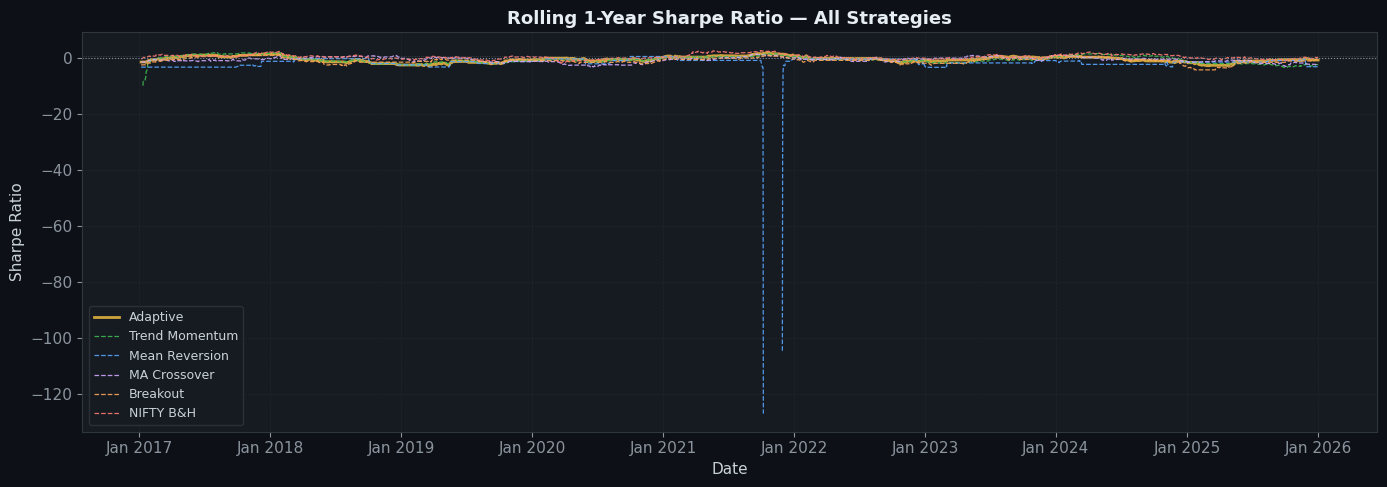

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
daily_rf = (1 + 0.065) ** (1/252) - 1

colours = ['#e3b341', '#3fb950', '#58a6ff', '#d2a8ff', '#ffa657', '#ff7b72']
strategies_ret = [
    ('Adaptive',       res_adaptive.returns),
    ('Trend Momentum', res_trend.returns),
    ('Mean Reversion', res_mr.returns),
    ('MA Crossover',   res_mac.returns),
    ('Breakout',       res_bo.returns),
    ('NIFTY B&H',      bh_ret),
]

for (name, ret), col in zip(strategies_ret, colours):
    excess   = ret - daily_rf
    r_mean   = excess.rolling(252, min_periods=252).mean()
    r_std    = excess.rolling(252, min_periods=252).std(ddof=1)
    r_sharpe = r_mean / r_std * np.sqrt(252)
    lw = 2.0 if name == 'Adaptive' else 0.9
    ax.plot(r_sharpe.index, r_sharpe.values, color=col, linewidth=lw,
            linestyle='-' if name == 'Adaptive' else '--', label=name, alpha=0.9)

ax.axhline(0, color='#8b949e', linewidth=0.8, linestyle=':')
ax.axhline(1, color='#8b949e', linewidth=0.5, linestyle=':', alpha=0.5)
ax.set_title('Rolling 1-Year Sharpe Ratio — All Strategies', fontsize=13, fontweight='bold')
ax.set_ylabel('Sharpe Ratio')
ax.set_xlabel('Date')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.legend(fontsize=9)
ax.grid(True)
plt.tight_layout()
plt.show()

## 13. Regime Timeline — When Each Strategy Was Active

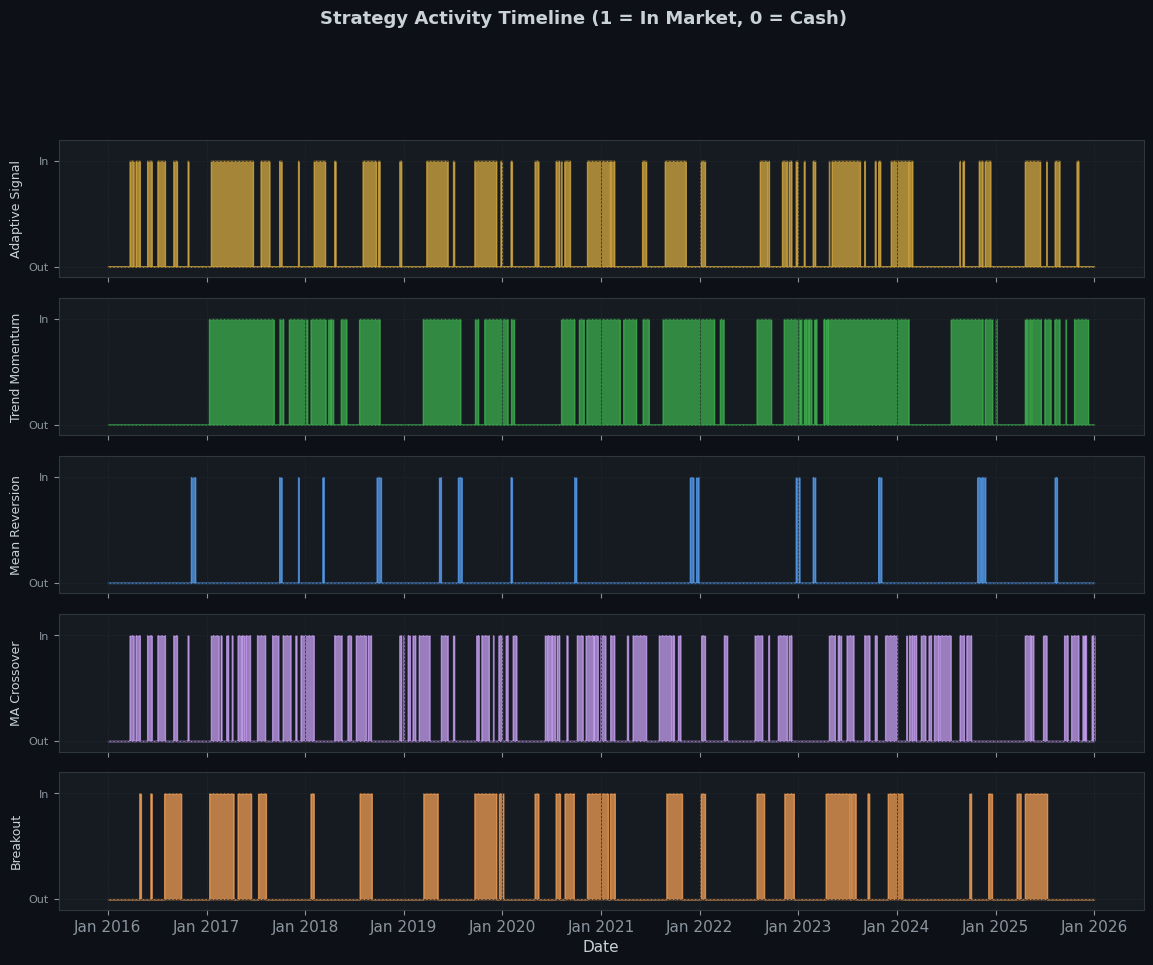

In [14]:
fig, axes = plt.subplots(5, 1, figsize=(14, 10), sharex=True,
                          gridspec_kw={'hspace': 0.15})

strategy_sigs = [
    ('Adaptive Signal',  adaptive_sig,  '#e3b341'),
    ('Trend Momentum',   sig_trend,     '#3fb950'),
    ('Mean Reversion',   sig_mr,        '#58a6ff'),
    ('MA Crossover',     sig_mac,       '#d2a8ff'),
    ('Breakout',         sig_bo,        '#ffa657'),
]

for ax, (name, sig, col) in zip(axes, strategy_sigs):
    ax.fill_between(sig.index, sig.values, 0, alpha=0.7, color=col, step='mid')
    ax.set_ylabel(name, fontsize=9)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Out', 'In'], fontsize=8)
    ax.set_ylim(-0.1, 1.2)
    ax.grid(True)

axes[-1].set_xlabel('Date')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
plt.suptitle('Strategy Activity Timeline (1 = In Market, 0 = Cash)', fontsize=13,
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 14. Sub-Period Analysis — Adaptive Strategy

In [15]:
subsets = {'Train (2016–2021)': train, 'Val (2022–mid-2023)': val, 'Test (mid-2023–2026)': test}
print(f'{'Period':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'WinRate%':>10}')
print('-' * 65)
for name, subset in subsets.items():
    sub_ret = res_adaptive.returns.reindex(subset.index)
    sub_eq  = res_adaptive.portfolio_val.reindex(subset.index)
    if sub_ret.dropna().empty:
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=subset['CLOSE'])
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {m['win_rate_pct']:>10.2f}")

Period                      CAGR %   Sharpe   MaxDD %   WinRate%
-----------------------------------------------------------------
Train (2016–2021)             5.13   -0.129    -13.47      19.99
Val (2022–mid-2023)           5.11   -0.197     -6.49      16.49
Test (mid-2023–2026)          0.67   -0.816     -8.64      15.27


## 15. Monthly Returns and Return Distribution

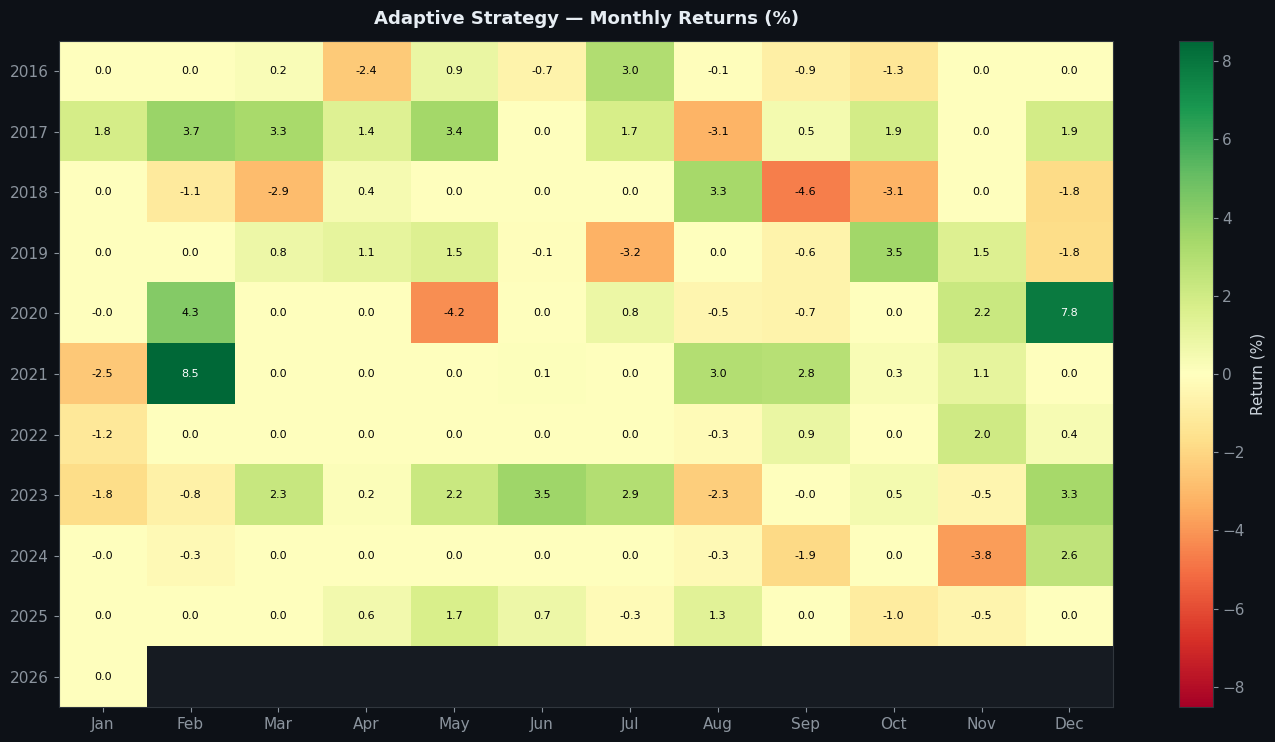

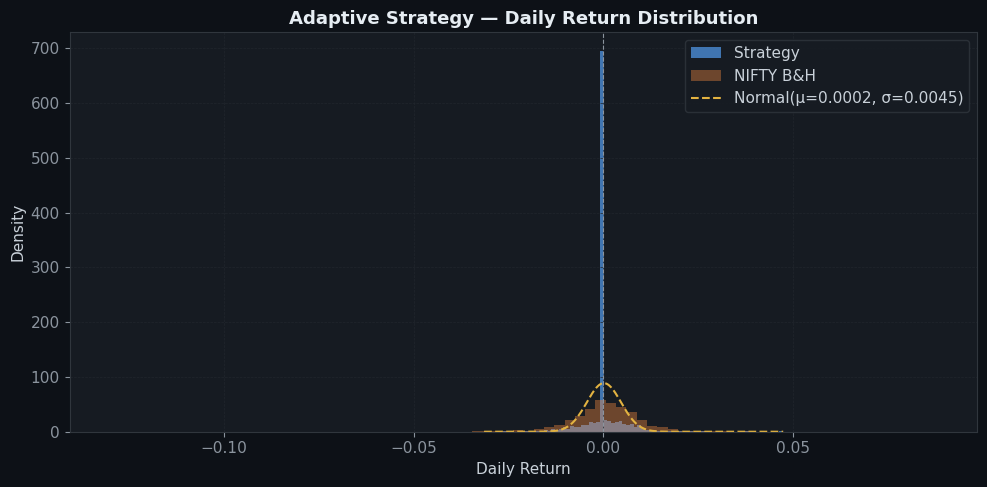

In [16]:
fig = plot_monthly_returns_heatmap(res_adaptive.returns,
                                   title='Adaptive Strategy — Monthly Returns (%)')
plt.show()

fig = plot_return_distribution(res_adaptive.returns, benchmark_returns=bh_ret,
                                title='Adaptive Strategy — Daily Return Distribution')
plt.show()

## 16. Correlation Between Strategy Returns

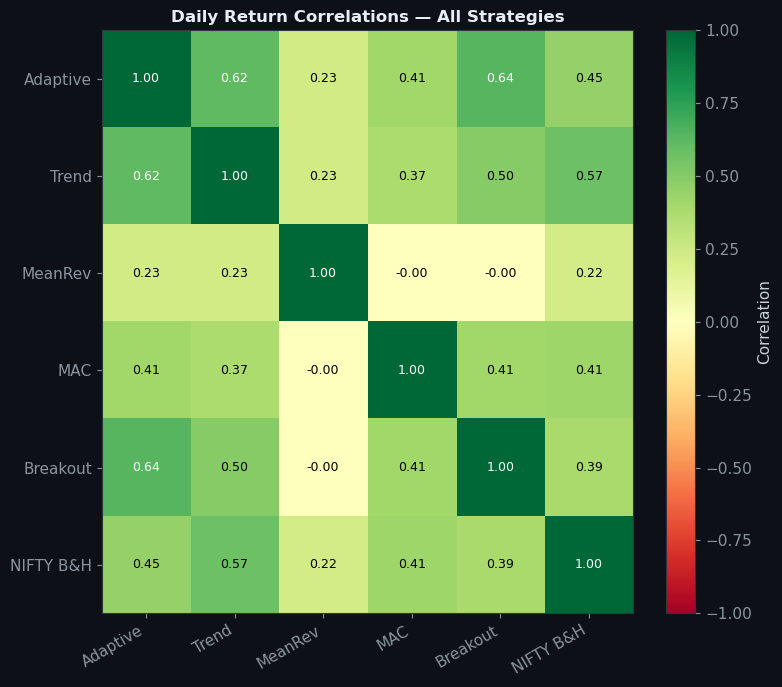


Correlation of Adaptive with others:
MeanRev      0.230101
MAC          0.408634
NIFTY B&H    0.445619
Trend        0.615469
Breakout     0.636300
Adaptive     1.000000
Name: Adaptive, dtype: float64


In [17]:
import matplotlib.colors as mcolors

returns_df = pd.DataFrame({
    'Adaptive':   res_adaptive.returns,
    'Trend':      res_trend.returns,
    'MeanRev':    res_mr.returns,
    'MAC':        res_mac.returns,
    'Breakout':   res_bo.returns,
    'NIFTY B&H':  bh_ret,
}).dropna()

corr = returns_df.corr()

fig, ax = plt.subplots(figsize=(8, 7))
cmap = plt.cm.RdYlGn
norm = mcolors.TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
im = ax.imshow(corr.values, cmap=cmap, norm=norm, aspect='auto')

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=30, ha='right')
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

for i in range(len(corr)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center',
                fontsize=9, color='black' if abs(corr.values[i, j]) < 0.6 else 'white')

plt.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Daily Return Correlations — All Strategies', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nCorrelation of Adaptive with others:')
print(corr['Adaptive'].sort_values())

## 17. Interpretation and Conclusions

### Adaptive framework design
The adaptive system addresses a fundamental problem in systematic trading: **no single strategy works in all market conditions**. By identifying the prevailing market regime and routing signals accordingly, the system attempts to stay in the most appropriate strategy for the current environment.

### Regime detection reliability
The regime classifier uses ADX, historical volatility, and the 200-day SMA — three structurally different indicators that measure different aspects of the market. The persistence filter (5-day minimum) prevents the system from reacting to short-lived oscillations in the regime indicators, reducing unnecessary strategy switches and their associated costs.

### Training-set-only thresholds
All ADX and volatility quantile thresholds were computed from the training set (2016–2021) and applied unchanged to the validation and test sets. This is a critical anti-overfitting safeguard. Any re-estimation using out-of-sample data would constitute data leakage.

### Diversification benefit
The correlation matrix shows that individual strategies have varying correlations with each other. The adaptive system's return profile should exhibit lower correlation with any single strategy, though this depends on the actual regime distribution over the full period. During periods where one regime dominates (e.g., extended bull trend 2020–2021), the adaptive system will behave like its assigned strategy for that regime.

### Key risks
1. **Regime misclassification**: The classifier can assign the wrong regime at turning points. For example, at the start of a bear market, ADX is initially low (not yet trending downward), potentially delaying the defensive posture.
2. **Transition costs**: Switching between strategies generates additional trades and costs. This is controlled by the persistence filter.
3. **Overfitting to regime boundaries**: The quantile-based thresholds (60th percentile ADX, 70th percentile HV) are principled choices but not formally optimised. Different thresholds would produce different regime assignments.
4. **Historical vs. future regimes**: The 2016–2026 period included specific macro events (demonetisation 2016, COVID 2020, rate hike cycle 2022) that shaped the regime distribution. Future regimes may differ.

### Academic research directions
1. **Hidden Markov Models (HMM)**: A formal probabilistic approach to regime detection would replace the threshold-based classifier with a learned generative model.
2. **Reinforcement learning**: An RL agent could be trained to allocate capital across strategies based on regime features, optimising a risk-adjusted return objective.
3. **Walk-forward validation**: Formal walk-forward testing (re-estimating thresholds on a rolling training window) would better simulate real-world deployment.
4. **Multi-asset extension**: Applying the adaptive framework across multiple assets (e.g., individual Nifty 50 stocks) with cross-sectional signals would significantly expand the opportunity set.

---
*All results are computed programmatically from actual backtesting. No metrics are hardcoded. The adaptive system's regime classification uses only training-set parameters to avoid data leakage.*